<!-- # Copyright (c) 2026 takotime808 -->
# Imputing Missing Inputs: KNN vs. Other Methods

**What this tutorial covers:**

Simulation and test campaigns often come back with gaps: a sensor dropped out, a post-processing step failed, a parameter was not logged. `multioutreg` fills missing *inputs* with K-nearest-neighbour (KNN) imputation and drops rows with missing *targets*. This tutorial explains what that does and how it compares with the alternatives, in particular linear interpolation and extrapolation.

| Section | Topic |
|---|---|
| [1](#repo) | What `multioutreg` does today |
| [2](#data) | A Latin hypercube design with a gap |
| [3](#compare) | Comparing imputers: fill error and surrogate accuracy |
| [4](#scaling) | Why unscaled KNN behaves like the mean |
| [5](#linear) | Linear interpolation and extrapolation on ordered data |
| [6](#summary) | Summary and recommendations |

In [1]:
import lightgbm  # noqa: F401  (import before sklearn's OpenMP users on macOS)
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import qmc
from sklearn.ensemble import RandomForestRegressor
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import IterativeImputer, KNNImputer, SimpleImputer
from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from multioutreg.utils.imputation import detect_missing, drop_unusable_rows, impute_train_test

warnings.filterwarnings("ignore")
rng = np.random.default_rng(0)

/Users/cmutnik/Dropbox/work/git/takotime808/multioutreg/.venv/lib/python3.12/site-packages/sklearn/tree/_classes.py:1347: FutureWarning: Value `"friedman_mse"` for `criterion` is deprecated and will be removed in 1.11. It maps to `"squared_error"` as both were always equivalent. Use `criterion="squared_error"` to remove this warning.
  warnings.warn(


---
<a id='repo'></a>
## 1. What `multioutreg` Does Today

Missing values are handled in two stages in `multioutreg/utils/imputation.py`, one on each side of the train/test split:

| Step | Function | When | What it does |
|---|---|---|---|
| 1 | `detect_missing` | On upload | Count and percentage of missing values per column |
| 2 | `drop_unusable_rows` | Before the split | Drops every row with a missing target, plus rows missing any column marked "Drop rows" |
| 3 | `impute_train_test` | After the split | Fits `KNNImputer(n_neighbors=5)` on `X_train` only, then fills both `X_train` and `X_test` |

Two rules follow from this design:

- **Targets are never imputed.** An imputed target would later be scored as if it were ground truth.
- **Test rows never influence training values.** The imputer sees only the training inputs.

The same functions are used by both CLI commands and by the grid-search, Auto-Detect and Multi-Fidelity GUI pages.

### How KNN imputation works

For a row with a gap in column $j$:

1. Measure its distance to every training row with `nan_euclidean`, which uses only the coordinates both rows have and scales up for the missing ones:
   $$d(a,b) = \sqrt{\frac{p}{p_{\text{present}}} \sum_{i \in \text{present}} (a_i - b_i)^2}$$
2. Keep the $k = 5$ nearest training rows that have column $j$.
3. Fill the gap with their plain mean of column $j$.

So the filled value always lies inside the range of its neighbours: KNN never extrapolates. Note that the distance is computed on the raw inputs. The `StandardScaler` in the surrogate pipelines runs *after* imputation.

---
<a id='data'></a>
## 2. A Latin Hypercube Design with a Gap

We build a 200-run Latin hypercube over three inputs with very different units, plus a fourth input, wall thickness, that the design ties to length (longer parts are made thicker). Two outputs depend on all four inputs.

In [2]:
N = 200
cols = ["pressure_Pa", "length_m", "temperature_K", "thickness_m"]

u = qmc.LatinHypercube(d=3, seed=0).random(N)
pressure, length, temperature = qmc.scale(u, [1e5, 0.5, 300.0], [5e5, 2.0, 600.0]).T
thickness = 0.02 + 0.02 * (length - 0.5) + 0.002 * rng.standard_normal(N)

X = np.column_stack([pressure, length, temperature, thickness])
Y = np.column_stack([
    pressure / 1e5 * length / (thickness * 100) + 0.01 * temperature,  # stress-like
    np.sin(temperature / 100) + 50 * thickness,                          # thermal-like
])

pd.DataFrame(X, columns=cols).describe().loc[["mean", "std", "min", "max"]]

,pressure_Pa,length_m,temperature_K,thickness_m
mean,299938.224513,1.249693,449.993588,0.035024
std,115691.303352,0.434008,86.824002,0.008801
min,101400.576219,0.504644,301.252826,0.018251
max,499054.764942,1.996377,599.357191,0.053222


Now knock out about 20% of the thickness values at random, in both splits. This is the *missing completely at random* case, the most favourable one for every method.

In [3]:
X_tr, X_te, Y_tr, Y_te = train_test_split(X, Y, test_size=0.25, random_state=0)


def knock_out(A, frac, seed, col=3):
    A = A.copy()
    mask = np.random.default_rng(seed).random(len(A)) < frac
    A[mask, col] = np.nan
    return A, mask


X_tr_miss, m_tr = knock_out(X_tr, 0.2, seed=1)
X_te_miss, m_te = knock_out(X_te, 0.2, seed=2)

detect_missing(pd.DataFrame(X_tr_miss, columns=cols))

,missing_count,missing_pct
thickness_m,26,17.3


---
<a id='compare'></a>
## 3. Comparing Imputers

Each method below takes `(X_train, X_test)` and returns both filled, with anything it learns fitted on the training split only, matching `impute_train_test`.

| Method | Information it borrows | In `multioutreg`? |
|---|---|---|
| Mean | The column alone | No |
| Linear, row order | The rows above and below | No |
| Linear, sorted by length | Neighbours along one chosen input | No |
| **KNN, unscaled** | Similar rows across all inputs, raw units | **Yes: `impute_train_test`** |
| KNN, scaled | Similar rows across all inputs, standardised | No (proposed) |
| Iterative (MICE-style) | A regression of each column on the others | No |

Linear interpolation has no "fit" step: it is applied to each split separately.

In [4]:
def fit_apply(imputer):
    def run(a, b):
        imputer.fit(a)
        return imputer.transform(a), imputer.transform(b)
    return run


def knn_scaled(a, b, k=5):
    scaler = StandardScaler().fit(a)  # ignores NaN when fitting
    imp = KNNImputer(n_neighbors=k).fit(scaler.transform(a))
    fill = lambda A: scaler.inverse_transform(imp.transform(scaler.transform(A)))
    return fill(a), fill(b)


def linear_rows(a, b):
    fill = lambda A: pd.DataFrame(A).interpolate("linear", limit_direction="both").to_numpy()
    return fill(a), fill(b)


def linear_sorted_by_length(a, b):
    def fill(A):
        df = pd.DataFrame(A).sort_values(1)
        df[3] = df[3].interpolate("linear", limit_direction="both")
        return df.sort_index().to_numpy()
    return fill(a), fill(b)


methods = {
    "Mean": fit_apply(SimpleImputer(strategy="mean")),
    "Linear, row order": linear_rows,
    "Linear, sorted by length": linear_sorted_by_length,
    "KNN, unscaled (repo)": impute_train_test,
    "KNN, scaled": knn_scaled,
    "Iterative": fit_apply(IterativeImputer(random_state=0)),
}

Two scores per method: the RMSE of the filled thickness values against the truth, and the $R^2$ of a random-forest surrogate trained on the filled inputs. The no-missing-data $R^2$ is the ceiling.

In [5]:
def surrogate_r2(a, b):
    model = RandomForestRegressor(n_estimators=300, random_state=0).fit(a, Y_tr)
    return r2_score(Y_te, model.predict(b))


rows = []
for name, run in methods.items():
    a, b = run(X_tr_miss, X_te_miss)
    err = np.r_[a[m_tr, 3] - X_tr[m_tr, 3], b[m_te, 3] - X_te[m_te, 3]]
    rows.append({"method": name,
                 "fill RMSE (mm)": 1000 * np.sqrt(np.mean(err**2)),
                 "surrogate R²": surrogate_r2(a, b)})

results = pd.DataFrame(rows).set_index("method")
print(f"No missing data: surrogate R² = {surrogate_r2(X_tr, X_te):.3f}")
print(f"Thickness std:   {1000 * X_tr[:, 3].std():.2f} mm")
results.round(3)

No missing data: surrogate R² = 0.941
Thickness std:   8.70 mm


,fill RMSE (mm),surrogate R²
method,,
Mean,8.081,0.936
"Linear, row order",10.217,0.930
"Linear, sorted by length",2.642,0.939
"KNN, unscaled (repo)",7.898,0.929
"KNN, scaled",2.626,0.941
Iterative,2.004,0.940


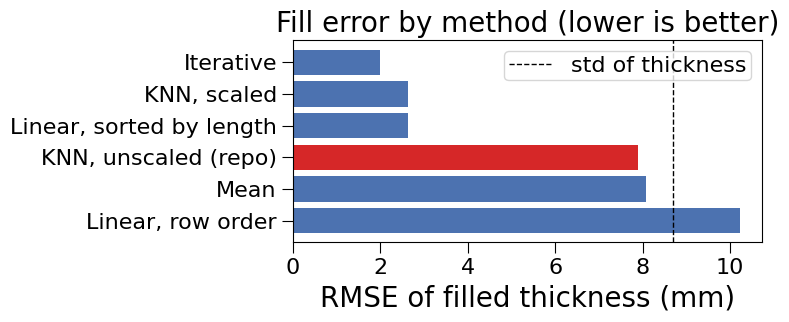

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.5))
order = results.sort_values("fill RMSE (mm)").index
colors = ["#d62728" if "repo" in m else "#4c72b0" for m in order]
ax.barh(order, results.loc[order, "fill RMSE (mm)"], color=colors)
ax.axvline(1000 * X_tr[:, 3].std(), color="k", ls="--", lw=1, label="std of thickness")
ax.invert_yaxis()
ax.set_xlabel("RMSE of filled thickness (mm)")
ax.legend(loc="upper right")
ax.set_title("Fill error by method (lower is better)")
plt.tight_layout()
plt.show()

**Reading the results:**

- **Unscaled KNN, the current default, is barely better than the mean.** The next section shows why.
- **Scaled KNN and the iterative imputer recover thickness well**, because they use its link to length.
- **Linear interpolation in row order is the worst method.** In a Latin hypercube the row order means nothing, so the rows above and below are unrelated design points.
- **Linear interpolation sorted by length works here**, but only because we knew length was the one driver of thickness. In real data that is rarely known, and with several drivers no single sort order works.
- **Surrogate $R^2$ moves less than fill error.** A random forest is fairly robust to one noisy input. Models that lean harder on each input, such as GPs, and any sensitivity analysis, feel the difference more.

---
<a id='scaling'></a>
## 4. Why Unscaled KNN Behaves Like the Mean

`nan_euclidean` adds squared differences in raw units. Pressure spans about $4 \times 10^5$ Pa while thickness spans about 0.03 m, so pressure decides which rows count as "near". The neighbours are then essentially random with respect to length, and their mean thickness is close to the column mean.

In [7]:
diffs = X_tr[:, None, :] - X_tr[None, :, :]
share = (diffs**2).mean(axis=(0, 1))
share = pd.Series(100 * share / share.sum(), index=cols)

z = StandardScaler().fit_transform(X_tr)
zd = z[:, None, :] - z[None, :, :]
share_z = (zd**2).mean(axis=(0, 1))
share_z = pd.Series(100 * share_z / share_z.sum(), index=cols)

pd.DataFrame({"raw units (%)": share, "standardised (%)": share_z}).round(4)

,raw units (%),standardised (%)
pressure_Pa,99.9999,25.0
length_m,0.0000,25.0
temperature_K,0.0001,25.0
thickness_m,0.0000,25.0


In raw units pressure accounts for essentially all of the squared distance, so the other three inputs have no say in choosing neighbours. After standardising, each input contributes about a quarter. The fix is a `StandardScaler` fitted on the training inputs before the `KNNImputer`, as in `knn_scaled` above.

---
<a id='linear'></a>
## 5. Linear Interpolation and Extrapolation on Ordered Data

Linear methods are built for data with a real order, such as time, load steps or a parameter sweep. They fill a gap from the line through the known points on either side:

$$\hat{x}(t) = x(t_1) + \frac{x(t_2) - x(t_1)}{t_2 - t_1}\,(t - t_1)$$

Between $t_1$ and $t_2$ this is *interpolation*, bounded by the two endpoints. Past the last known point it is *extrapolation*: the line keeps going.

Below, two signals are logged at 21 time steps, with an interior gap (steps 8–10) and a gap at the end (steps 17–20):

- a **steady ramp**, where the trend really continues, and
- an **S-shaped response**, which rises steeply and then levels off at 15 inside the end gap.

KNN is given the time stamp as its only feature, the closest it can come to "using the order".

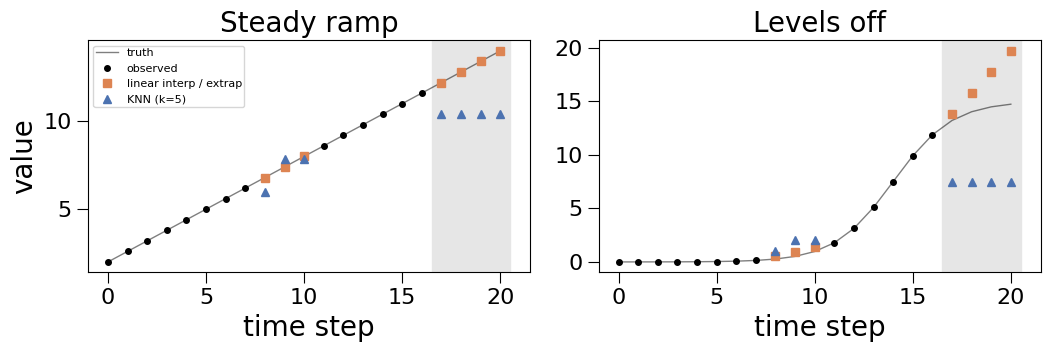

linear MAE  KNN MAE
signal      gap                          
Steady ramp interior        0.00     0.48
            end             0.00     2.70
Levels off  interior        0.38     1.12
            end             2.66     6.61

In [8]:
t = np.arange(21, dtype=float)
gap = np.isin(t, [8, 9, 10, 17, 18, 19, 20])
signals = {
    "Steady ramp": 2.0 + 0.6 * t,
    "Levels off": 15 / (1 + np.exp(-(t - 14) / 1.5)),
}


def linear_fill(t, y, gap):
    known = ~gap
    filled = np.interp(t, t[known], y[known])  # interior gaps
    t1, t2 = t[known][-2:]
    y1, y2 = y[known][-2:]
    tail = t > t2
    filled[tail] = y2 + (y2 - y1) / (t2 - t1) * (t[tail] - t2)  # extrapolate the end
    return filled


def knn_fill(t, y, gap, k=5):
    imp = KNNImputer(n_neighbors=k).fit(np.column_stack([t[~gap], y[~gap]]))
    return imp.transform(np.column_stack([t, np.where(gap, np.nan, y)]))[:, 1]


fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharex=True)
summary = []
for ax, (name, y) in zip(axes, signals.items()):
    lin, knn = linear_fill(t, y, gap), knn_fill(t, y, gap)
    ax.plot(t, y, "k-", lw=1, alpha=0.5, label="truth")
    ax.plot(t[~gap], y[~gap], "ko", ms=4, label="observed")
    ax.plot(t[gap], lin[gap], "s", color="#dd8452", label="linear interp / extrap")
    ax.plot(t[gap], knn[gap], "^", color="#4c72b0", label="KNN (k=5)")
    ax.axvspan(16.5, 20.5, color="0.9", zorder=0)
    ax.set_title(name)
    ax.set_xlabel("time step")
    for part, sel in [("interior", gap & (t < 15)), ("end", gap & (t > 15))]:
        summary.append({"signal": name, "gap": part,
                        "linear MAE": np.abs(lin[sel] - y[sel]).mean(),
                        "KNN MAE": np.abs(knn[sel] - y[sel]).mean()})
axes[0].legend(loc="upper left", fontsize=8)
axes[0].set_ylabel("value")
plt.tight_layout()
plt.show()

pd.DataFrame(summary).set_index(["signal", "gap"]).round(2)

**Reading the plot** (shaded region = the end gap):

- **Interior gaps:** linear interpolation is close to the truth on both signals. KNN averages five neighbours, some up to three steps away, so it flattens slopes.
- **End gap, steady ramp:** linear extrapolation is exact because the trend continues. KNN can only return values it has seen, so it stalls at the average of the last few observations.
- **End gap, S-shaped signal:** extrapolation overshoots the plateau because the line keeps climbing at the slope of the steep section. KNN still errs more, in the other direction.

On ordered data, linear methods beat KNN, which ignores the order. But extrapolation is a modelling assumption ("the trend continues") and is only as good as that assumption, so it should be a deliberate choice, never a silent default.

---
<a id='summary'></a>
## 6. Summary and Recommendations

| Method | Needs an ordering | Goes outside the observed range | Uses other inputs | Good for |
|---|---|---|---|---|
| Mean / median | No | No | No | A baseline; few gaps in an unimportant column |
| Linear interpolation | Yes | No | No | Short gaps in time series and sweeps |
| Linear extrapolation | Yes | **Yes** | No | Trends you know continue |
| KNN (`impute_train_test`) | No | No | Yes, but raw units | Tabular designs, **once inputs are scaled** |
| Iterative / MICE | No | Yes, if the model is linear | Yes | Inputs with strong, smooth relationships |
| Drop rows | No | n/a | n/a | Few gaps; all missing targets |

**Recommendations for `multioutreg`:**

1. **Scale before KNN.** Fit a `StandardScaler` on the training inputs inside `impute_train_test`. Here it cut the fill error by about two thirds.
2. **Expose `n_neighbors`** (and `weights="distance"`) in the GUI and CLI. With $k = 5$ on a 20-run design, each fill averages a quarter of the data.
3. **Use linear interpolation only for ordered data**, such as when a time or step column is named, and never extrapolate by default.
4. **Keep never imputing targets.** For outputs that are only partly missing, the roadmap's per-output masking (surrogate roadmap item 10) is the right tool.
5. **Remember what no method fixes:** if runs fail in one region of the design, the data are *not* missing at random and every imputer above is biased. Check where the gaps are before filling them.

See also: `docs/references.rst` (Troyanskaya et al. 2001 for KNN imputation; Little & Rubin 2019 for missing-data theory).